## 인구 데이터 전처리

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')
plt.rcParams['font.family']= 'NanumGothic' 
plt.rcParams['axes.unicode_minus']=False
# Load newly uploaded population data files for 2023 and 2024
path_2023 = "경기도 성남시_인구및세대_현황_20231231.csv"
path_2024 = "경기도 성남시_인구및세대_현황_20241231.csv"

# Reload using cp949 encoding
pop_2023 = pd.read_csv(path_2023, encoding='cp949')
pop_2024 = pd.read_csv(path_2024, encoding='cp949')

# Display column names to understand structure
pop_2023.columns.tolist(), pop_2024.columns.tolist()


(['구별',
  '동',
  '인구수_계',
  '인구수_남',
  '인구수_여',
  '19세 이상_계',
  '19세 이상_남',
  '19세 이상_여',
  '65세 이상_계',
  '65세 이상_남자',
  '65세 이상_여자',
  '세대수',
  '재외국민',
  '데이터기준일자'],
 ['구별',
  '동',
  '인구수_계',
  '인구수_남',
  '인구수_여',
  '19세 이상_계',
  '19세 이상_남',
  '19세 이상_여',
  '65세 이상_계',
  '65세 이상_남자',
  '65세 이상_여자',
  '세대수',
  '재외국민',
  '데이터기준일자'])

In [ ]:
pop_5yrs= pd.read_csv('동별_연령별_인구_외국인제외__20250504042228.csv', encoding='utf-8')
pop_5yrs

In [ ]:
# 필터링
pop_5yrs_filtered = pop_5yrs[~pop_5yrs['연령별(1)'].isin(['연령별(1)', '합계', '계'])]

# 필요한 연령대만 필터링
under_15_ages = ['0-4세', '5-9세', '10-14세']
over_65_ages = ['65-69세', '70-74세', '75-79세', '80-84세', '85-89세', '90-94세', '95-99세', '100이상']

# 연령대 필터 적용
under_15_df = pop_5yrs_filtered[pop_5yrs_filtered['연령별(1)'].isin(under_15_ages)]
over_65_df = pop_5yrs_filtered[pop_5yrs_filtered['연령별(1)'].isin(over_65_ages)]

# 필요한 연도만 추출 (2019~2023)
years = ['2019', '2020', '2021', '2022', '2023']

# 동별로 연도별 합계를 만든다
under_15_by_year = under_15_df.groupby('동별')[years].sum().reset_index()
over_65_by_year = over_65_df.groupby('동별')[years].sum().reset_index()

# 결과 확인
under_15_by_year.head(), over_65_by_year.head()

(     동별          2019         2020         2021         2022        2023
 0   고등동     297144162    459242218    683448300    730492318   738610366
 1  구미1동     653758789    600756771    519710737    524630705   480582701
 2   구미동  110412361350  98312431318  86511931225  82011451216  7069911187
 3   금곡동   10309351103   9199841043   8399261019    786938987  7139071014
 4  금광1동     209204235    217214225    183193210    766538364  1258979563,
      동별                     2019                      2020  \
 0   고등동        33524913781521931        447314177108642842   
 1  구미1동     62054639131916570192      70553440729518382142   
 2   구미동  12991163965732422206429  140911599647614652225411   
 3   금곡동  12871088854667346161365   14361121884695372167375   
 4  금광1동     34928819512653191029       4063031811345523531   
 
                       2021                     2022                      2023  
 0       526361223125712231       550388241150752942        606425291161734052  
 1     782497

In [ ]:

# 필터링
pop_5yrs_filtered = pop_5yrs[~pop_5yrs['연령별(1)'].isin(['연령별(1)', '합계', '계'])]

# 필요한 연령대만 필터링
under_15_ages = ['0-4세', '5-9세', '10-14세']
over_65_ages = ['65-69세', '70-74세', '75-79세', '80-84세', '85-89세', '90-94세', '95-99세', '100이상']
# 먼저 15세 미만과 65세 이상 인구에 대해 연도별 값을 숫자형으로 변환
for year in years:
    under_15_df[year] = pd.to_numeric(under_15_df[year], errors='coerce')
    over_65_df[year] = pd.to_numeric(over_65_df[year], errors='coerce')

# 동별로 연도별 합계를 재계산
under_15_by_year = under_15_df.groupby('동별')[years].sum().reset_index()
over_65_by_year = over_65_df.groupby('동별')[years].sum().reset_index()

# 결과 확인
under_15_by_year.head(), over_65_by_year.head()



(     동별  2019  2020  2021  2022  2023
 0   고등동   603   919  1431  1540  1714
 1  구미1동  2200  2127  1966  1859  1763
 2   구미동  3690  3544  3283  3181  2884
 3   금곡동  3068  2946  2784  2711  2634
 4  금광1동   648   656   586  1668  2800,
      동별    2019    2020    2021    2022    2023
 0   고등동   877.0  1144.0  1332.0  1439.0  1603.0
 1  구미1동  2132.0  2222.0  2315.0  2421.0  2534.0
 2   구미동  4838.0  5045.0  5178.0  5398.0  5584.0
 3   금곡동  4444.0  4717.0  4909.0  5056.0  5267.0
 4  금광1동  1069.0  1138.0  1159.0  1780.0  2495.0)

In [ ]:
from sklearn.linear_model import LinearRegression
import numpy as np

def predict_2024(df, target_name):
    """동별 연도별 데이터를 받아 2024년 예측값을 반환"""
    df_long = df.melt(id_vars='동별', var_name='연도', value_name=target_name)
    df_long['연도'] = df_long['연도'].astype(int)

    # 결과 저장용
    predictions = []

    for dong, group in df_long.groupby('동별'):
        group = group.dropna()
        if len(group) < 2:
            continue
        X = group[['연도']]
        y = group[target_name]
        model = LinearRegression().fit(X, y)
        pred = model.predict(np.array([[2024]]))[0]
        predictions.append({'동별': dong, f'{target_name}_2024': round(pred)})

    return pd.DataFrame(predictions)

# 2024년 예측값 생성
pred_under15 = predict_2024(under_15_by_year, '15세미만')
pred_over65 = predict_2024(over_65_by_year, '65세이상')

# 병합 후 고령화지수 계산
pred_df = pd.merge(pred_under15, pred_over65, on='동별', how='inner')
pred_df['2024_고령화지수'] = (pred_df['65세이상_2024'] / pred_df['15세미만_2024']) * 100
pred_df


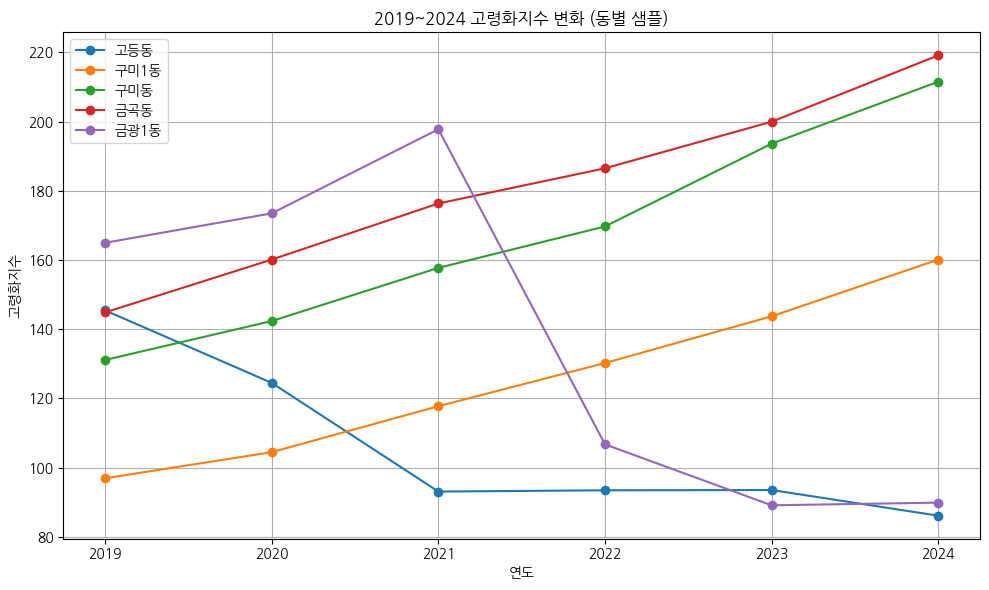

In [ ]:
import matplotlib.pyplot as plt

# 먼저 2019~2023 실제 고령화지수를 계산
# 15세 미만
under_15_by_year_long = under_15_by_year.melt(id_vars='동별', var_name='연도', value_name='15세미만')
over_65_by_year_long = over_65_by_year.melt(id_vars='동별', var_name='연도', value_name='65세이상')

# 병합 후 고령화지수 계산
long_df = pd.merge(under_15_by_year_long, over_65_by_year_long, on=['동별', '연도'])
long_df['고령화지수'] = (long_df['65세이상'] / long_df['15세미만']) * 100
long_df['연도'] = long_df['연도'].astype(int)

# 2024년 예측값 추가
pred_reshape = pred_df[['동별', '15세미만_2024', '65세이상_2024', '2024_고령화지수']].copy()
pred_reshape['연도'] = 2024
pred_reshape.rename(columns={
    '15세미만_2024': '15세미만',
    '65세이상_2024': '65세이상',
    '2024_고령화지수': '고령화지수'
}, inplace=True)

# 열 순서 맞추기
pred_reshape = pred_reshape[['동별', '연도', '15세미만', '65세이상', '고령화지수']]

# 기존 데이터와 병합
full_df = pd.concat([long_df, pred_reshape], ignore_index=True)

# 시각화를 위해 5개 정도 동을 임의로 선택
sample_dongs = full_df['동별'].dropna().unique()[:5]
fig, ax = plt.subplots(figsize=(10, 6))

for dong in sample_dongs:
    subset = full_df[full_df['동별'] == dong]
    ax.plot(subset['연도'], subset['고령화지수'], marker='o', label=dong)

ax.set_title("2019~2024 고령화지수 변화 (동별 샘플)")
ax.set_xlabel("연도")
ax.set_ylabel("고령화지수")
ax.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


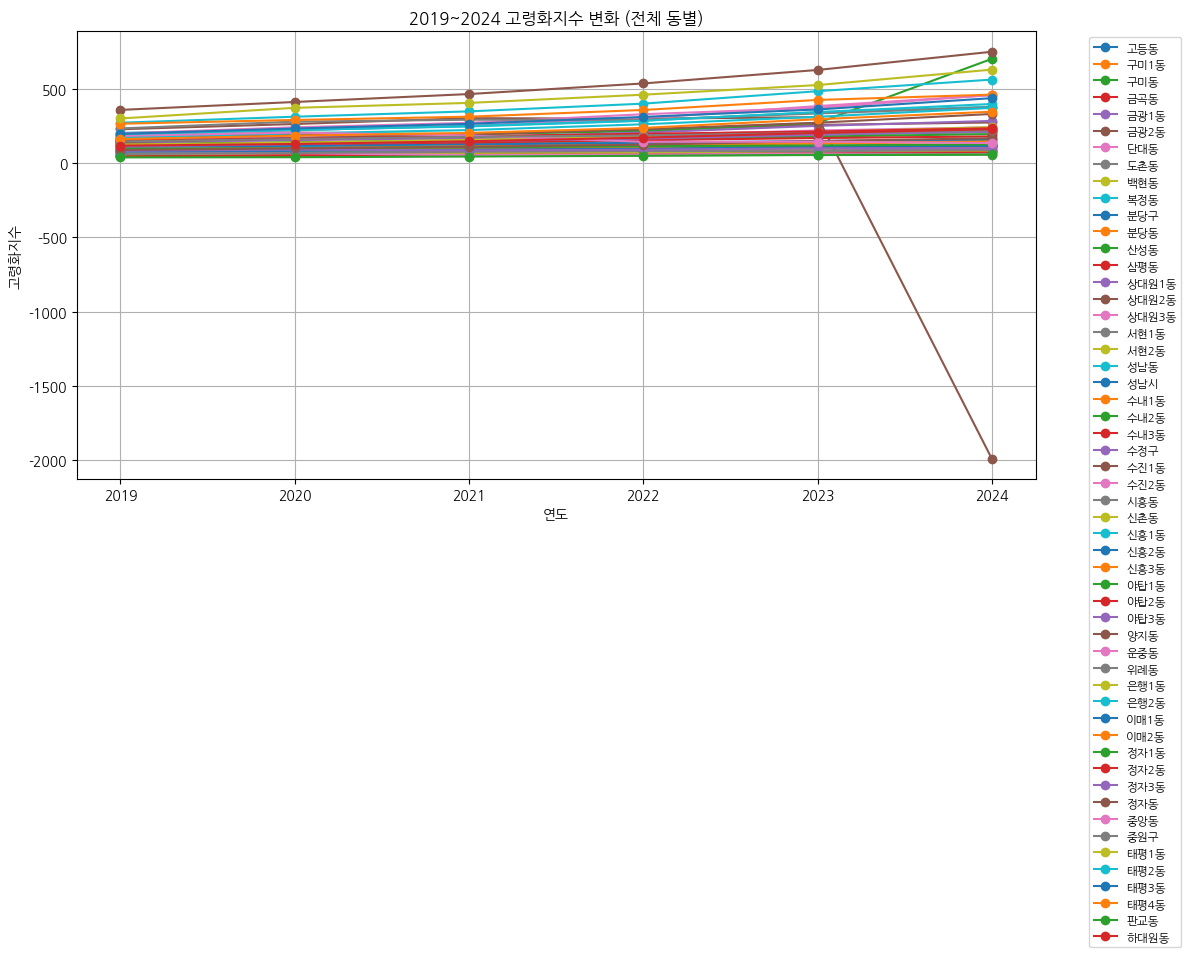

In [ ]:
# 전체 동에 대해 2019~2024 고령화지수 시계열 그래프 생성
fig, ax = plt.subplots(figsize=(12, 8))

# 동별 선을 모두 그린다
for dong in sorted(full_df['동별'].dropna().unique()):
    subset = full_df[full_df['동별'] == dong]
    ax.plot(subset['연도'], subset['고령화지수'], marker='o', label=dong)

# 그래프 꾸미기
ax.set_title("2019~2024 고령화지수 변화 (전체 동별)")
ax.set_xlabel("연도")
ax.set_ylabel("고령화지수")
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small', ncol=1)
plt.grid(True)
plt.tight_layout()
plt.show()


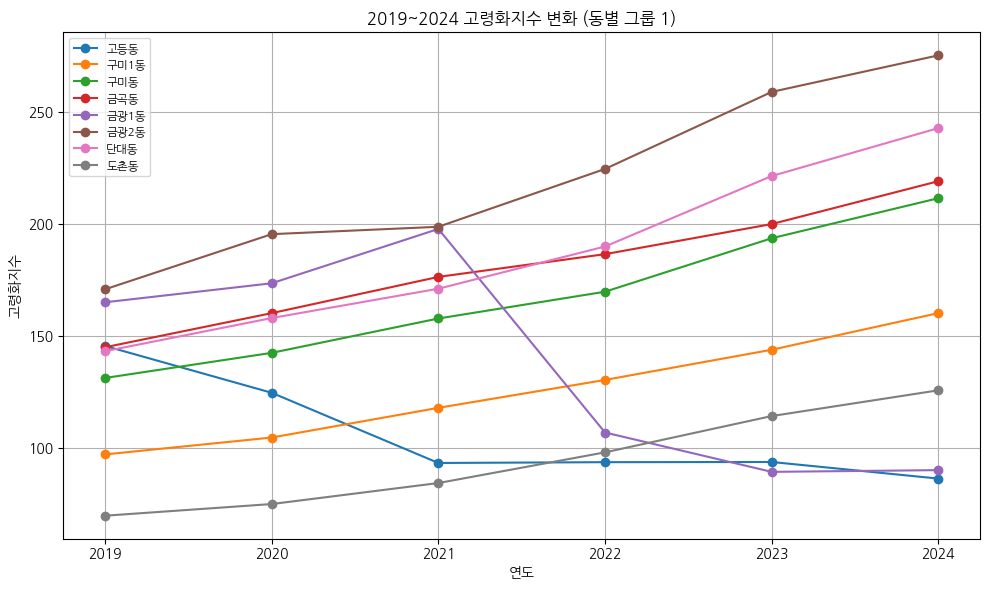

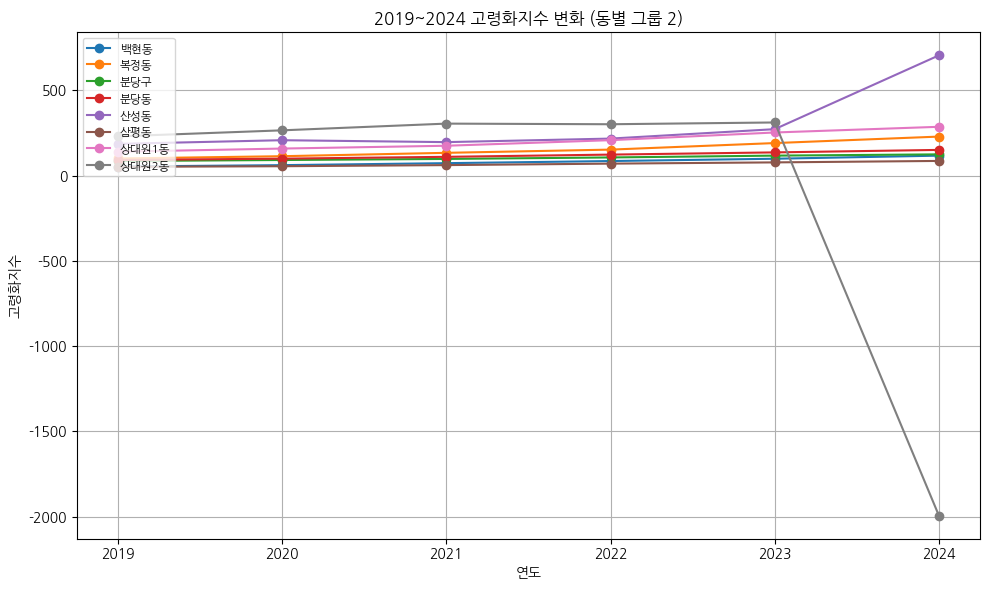

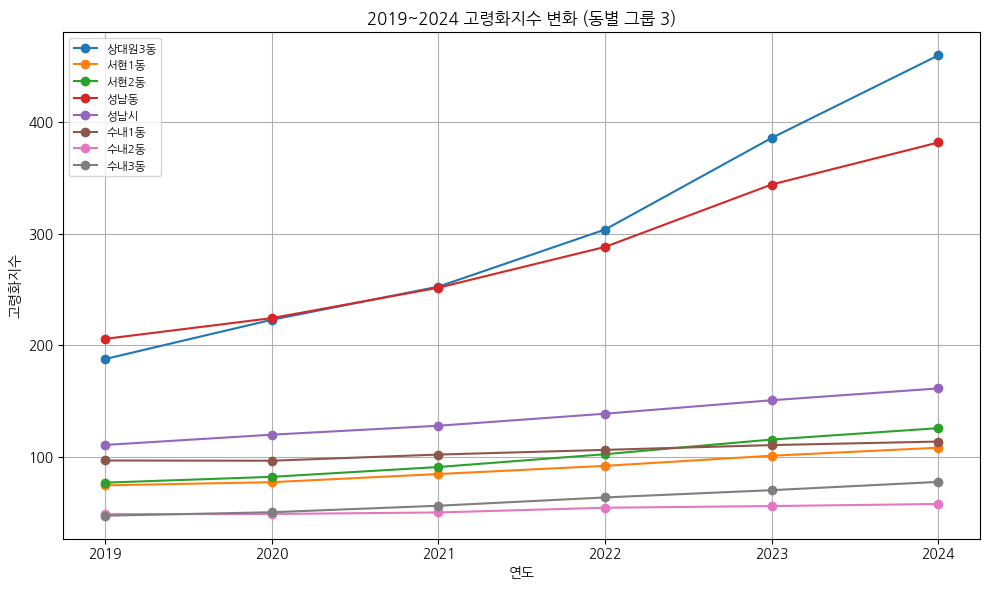

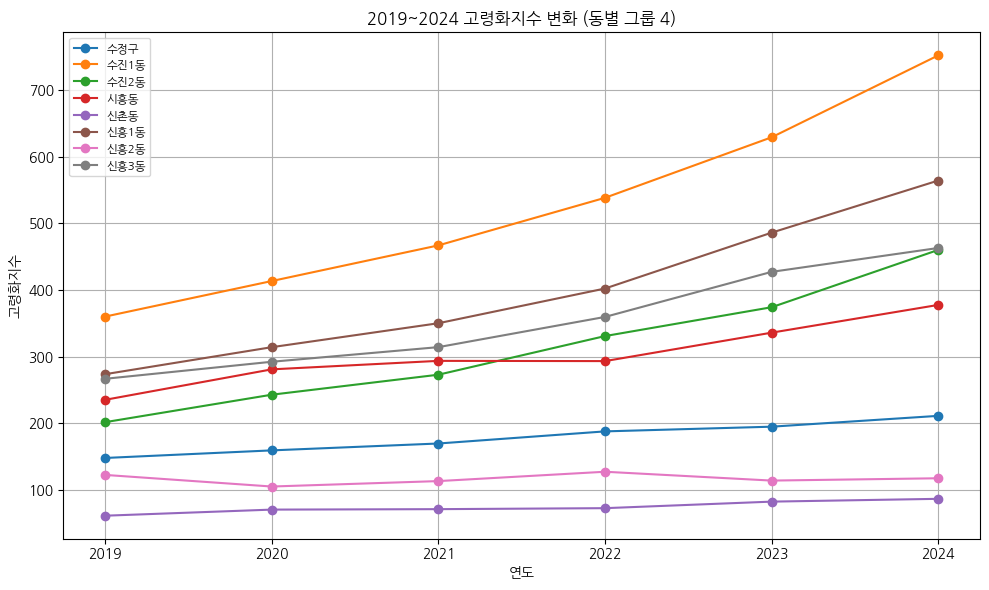

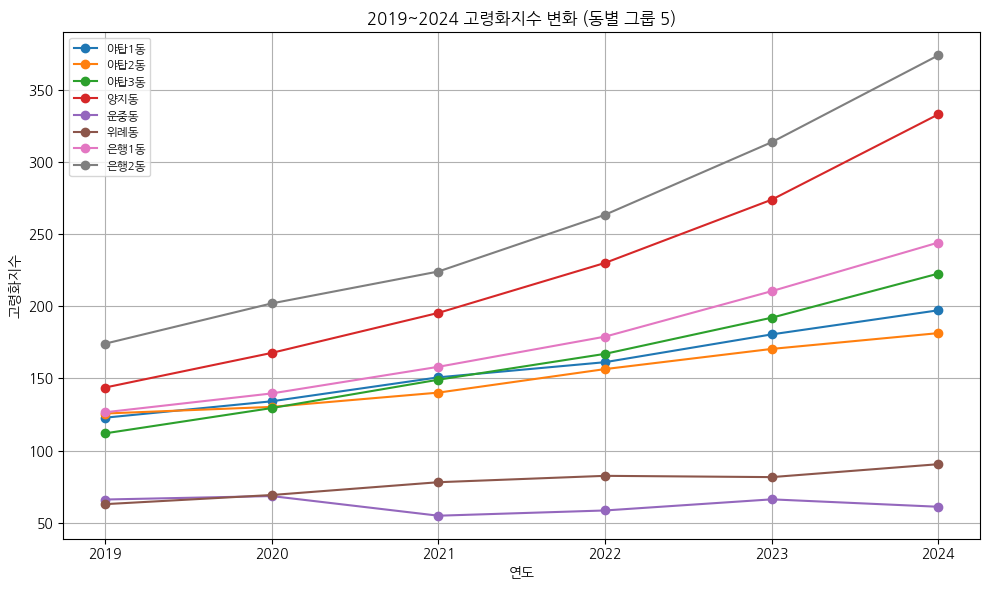

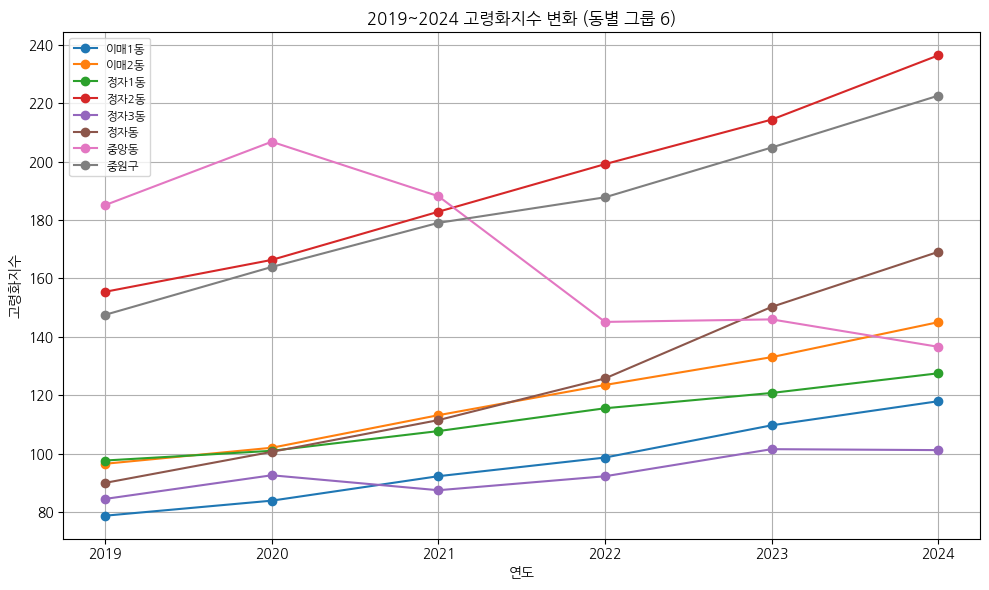

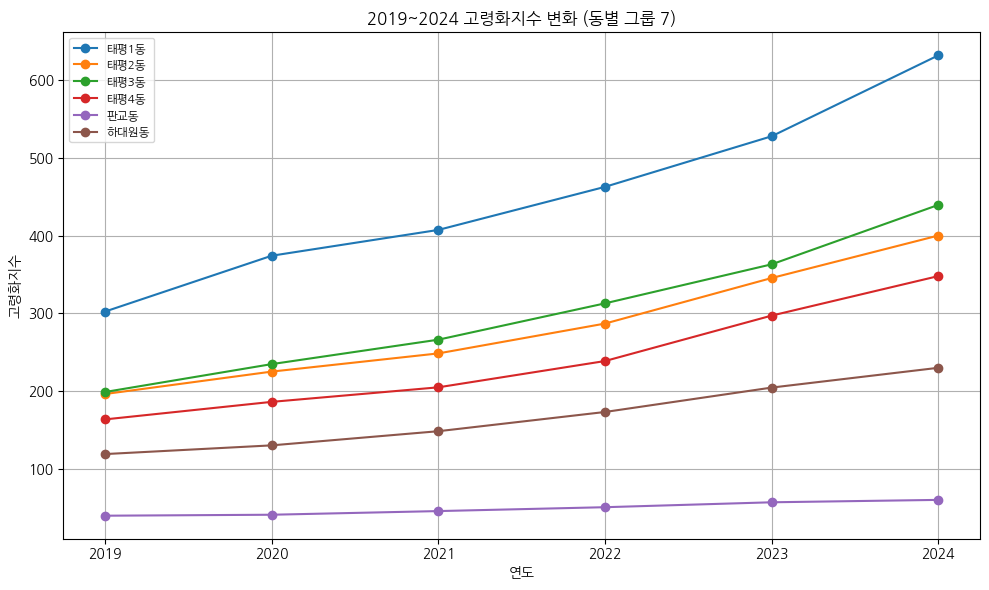

In [ ]:
# 동 이름 목록을 8개씩 나누기
dong_list = sorted(full_df['동별'].dropna().unique())
dong_chunks = [dong_list[i:i + 8] for i in range(0, len(dong_list), 8)]

# 각 그룹별로 그래프 생성
figures = []

for i, chunk in enumerate(dong_chunks):
    fig, ax = plt.subplots(figsize=(10, 6))
    for dong in chunk:
        subset = full_df[full_df['동별'] == dong]
        ax.plot(subset['연도'], subset['고령화지수'], marker='o', label=dong)

    ax.set_title(f"2019~2024 고령화지수 변화 (동별 그룹 {i+1})")
    ax.set_xlabel("연도")
    ax.set_ylabel("고령화지수")
    ax.legend(loc='upper left', fontsize='small')
    ax.grid(True)
    plt.tight_layout()
    figures.append(fig)

plt.show()


In [ ]:
## 상원대2동 이상

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

def predict_2024_polynomial(df, target_name, degree=2):
    """동별 연도별 데이터를 받아 다항 회귀 기반 2024년 예측값 반환"""
    df_long = df.melt(id_vars='동별', var_name='연도', value_name=target_name)
    df_long['연도'] = df_long['연도'].astype(int)

    predictions = []

    for dong, group in df_long.groupby('동별'):
        group = group.dropna()
        if len(group) < degree:
            continue
        X = group[['연도']]
        y = group[target_name]

        poly = PolynomialFeatures(degree)
        X_poly = poly.fit_transform(X)
        model = LinearRegression().fit(X_poly, y)
        X_pred = poly.transform(np.array([[2024]]))
        pred = model.predict(X_pred)[0]
        predictions.append({'동별': dong, f'{target_name}_2024': max(0, round(pred))})  # 음수는 0으로 보정

    return pd.DataFrame(predictions)

# 다항 회귀로 2024년 예측
poly_under15 = predict_2024_polynomial(under_15_by_year, '15세미만', degree=2)
poly_over65 = predict_2024_polynomial(over_65_by_year, '65세이상', degree=2)

# 병합 후 고령화지수 계산
poly_df = pd.merge(poly_under15, poly_over65, on='동별', how='inner')
poly_df['2024_고령화지수'] = (poly_df['65세이상_2024'] / poly_df['15세미만_2024'].replace(0, np.nan)) * 100

poly_df

In [ ]:
# 100명 이하일 경우 100명으로 보정하는 다항 회귀 (2차) 예측 수행
def predict_2024_polynomial_min100(df, target_name, degree=2):
    df_long = df.melt(id_vars='동별', var_name='연도', value_name=target_name)
    df_long['연도'] = df_long['연도'].astype(int)

    predictions = []

    for dong, group in df_long.groupby('동별'):
        group = group.dropna()
        if len(group) < degree:
            continue
        X = group[['연도']]
        y = group[target_name]

        poly = PolynomialFeatures(degree)
        X_poly = poly.fit_transform(X)
        model = LinearRegression().fit(X_poly, y)
        X_pred = poly.transform(np.array([[2024]]))
        pred = model.predict(X_pred)[0]
        pred = max(100, round(pred))  # 최소값 100으로 보정
        predictions.append({'동별': dong, f'{target_name}_2024': pred})

    return pd.DataFrame(predictions)

# 수정된 예측값 계산
min100_under15 = predict_2024_polynomial_min100(under_15_by_year, '15세미만')
min100_over65 = predict_2024_polynomial_min100(over_65_by_year, '65세이상')

# 병합 및 고령화지수 계산
min100_df = pd.merge(min100_under15, min100_over65, on='동별', how='inner')
min100_df['2024_고령화지수'] = (min100_df['65세이상_2024'] / min100_df['15세미만_2024']) * 100

min100_df

In [ ]:
# 기존 다항 회귀 기반 예측값을 복사
manual_df = min100_df.copy()

# 상대원2동의 2024년 예측값 수동 수정
manual_df.loc[manual_df['동별'] == '상대원2동', '15세미만_2024'] = 100
manual_df.loc[manual_df['동별'] == '상대원2동', '65세이상_2024'] = 200
manual_df.loc[manual_df['동별'] == '상대원2동', '2024_고령화지수'] = 200.0

# 결과 확인
manual_df

In [ ]:
# 2019~2023년 데이터에서 65세 이상 인구 추이 확보
over_65_long = over_65_by_year.melt(id_vars='동별', var_name='연도', value_name='65세이상')
over_65_long['연도'] = over_65_long['연도'].astype(int)

# 2024 수동 예측이 포함된 최신 데이터 사용
manual_over65 = manual_df[['동별', '65세이상_2024']].copy()
manual_over65['연도'] = 2024
manual_over65.rename(columns={'65세이상_2024': '65세이상'}, inplace=True)

# 전체 데이터 병합
all_years_over65 = pd.concat([over_65_long, manual_over65], ignore_index=True)
all_years_over65.sort_values(by=['동별', '연도'], inplace=True)

# 증감률 계산
all_years_over65['65세이상_증감률'] = all_years_over65.groupby('동별')['65세이상'].pct_change() * 100

# 피벗 형태로 증감률만 정리 (wide format)
rate_table = all_years_over65.pivot(index='동별', columns='연도', values='65세이상_증감률')

# 열 이름 변경
rate_table = rate_table.rename(columns={
    2020: '2020증감률',
    2021: '2021증감률',
    2022: '2022증감률',
    2023: '2023증감률',
    2024: '2024증감률'
}).reset_index()

rate_table

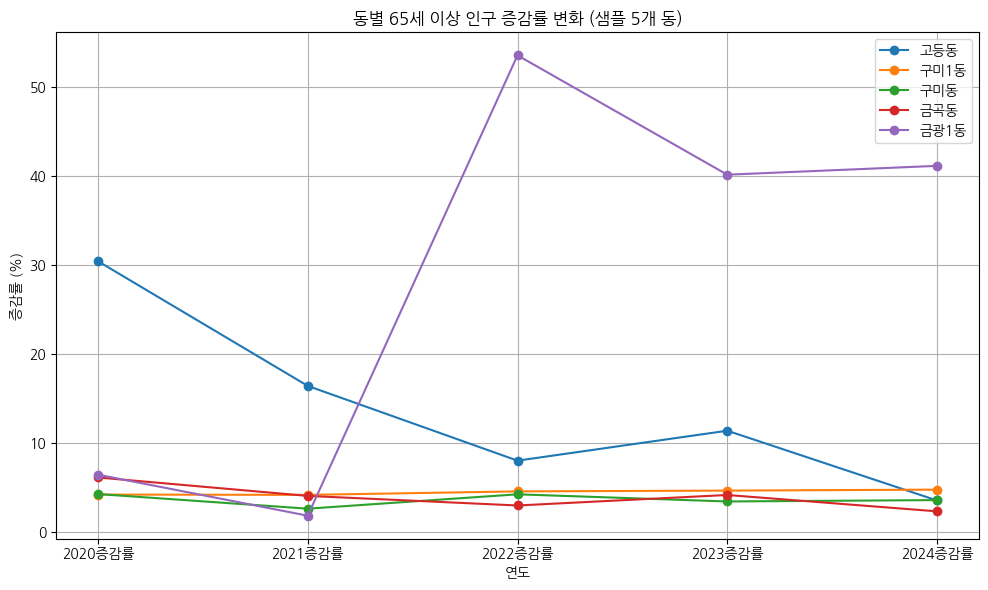

In [ ]:
import matplotlib.pyplot as plt

# 시각화를 위해 2020~2024년 증감률만 추출
melted_rate = rate_table.melt(id_vars='동별', value_vars=[
    '2020증감률', '2021증감률', '2022증감률', '2023증감률', '2024증감률'
], var_name='연도', value_name='증감률')

# 시각화 (동별 증감률 변화, 5개 샘플 동 먼저)
sample_dongs = melted_rate['동별'].unique()[:5]
fig, ax = plt.subplots(figsize=(10, 6))

for dong in sample_dongs:
    subset = melted_rate[melted_rate['동별'] == dong]
    ax.plot(subset['연도'], subset['증감률'], marker='o', label=dong)

ax.set_title("동별 65세 이상 인구 증감률 변화 (샘플 5개 동)")
ax.set_ylabel("증감률 (%)")
ax.set_xlabel("연도")
ax.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
rate_table.to_csv("65세이상_인구_증감률_동별요약.csv", index=False, encoding="utf-8-sig")


In [ ]:
# 2023년 인구 데이터 (15세 미만, 65세 이상, 고령화지수)
over_65_2023 = over_65_by_year[['동별', '2023']].rename(columns={'2023': '65세이상_2023'})
under_15_2023 = under_15_by_year[['동별', '2023']].rename(columns={'2023': '15세미만_2023'})
merged_2023 = pd.merge(over_65_2023, under_15_2023, on='동별', how='inner')
merged_2023['2023_고령화지수'] = (merged_2023['65세이상_2023'] / merged_2023['15세미만_2023']) * 100

# 2024년 예측 인구 데이터 (15세 미만, 65세 이상, 고령화지수)
merged_2024 = manual_df[['동별', '15세미만_2024', '65세이상_2024', '2024_고령화지수']]

# 병합
final_merged = pd.merge(merged_2023, merged_2024, on='동별', how='inner')


final_merged

In [ ]:
# 가정: final_merged 데이터프레임이 존재하고 2023, 2024년 고령화 관련 값들이 포함되어 있음

# 평균 컬럼 계산
final_merged['15세미만_평균'] = final_merged[['15세미만_2023', '15세미만_2024']].mean(axis=1)
final_merged['65세이상_평균'] = final_merged[['65세이상_2023', '65세이상_2024']].mean(axis=1)
final_merged['고령화지수_평균'] = final_merged[['2023_고령화지수', '2024_고령화지수']].mean(axis=1)

# 최종 컬럼 정리
avg_summary = final_merged[[
    '동별',
    '15세미만_평균',
    '65세이상_평균',
    '고령화지수_평균'
]]
avg_summary


In [ ]:
avg_summary.to_csv("고령화지수_평균.csv", index=False, encoding="utf-8-sig")